# Beach safety — allocating the extra $2M
Uses the models from `beach_models.ipynb` and the unit costs in `pricing.csv` to find the mix of lifeguard hours, drone hours, campaigns and first-aid training that **minimises expected severe incidents next year**.

**Costing assumptions** (all annual, year-one cash):

| Lever | Cost used | From pricing.csv |
|---|---|---|
| Casual lifeguard | $58 / h, any beach, any month | as given |
| Full-time lifeguard | $80,500 / FTE for 1,750 h spread evenly over 12 months | $80,000 + $500 recruitment |
| Drone hours | $45 / h while existing drone capacity lasts (120 h/month per drone) | casual operator |
| New drone kit | $3,450 per extra drone (one per 120 h/month) | $9,000 hardware over its 3-year life + $450 operator training |
| Campaign | $15,000 per postcode: campaign_idx → max(idx, 0.7) in Nov–Feb, every beach in the postcode | as given |
| First aid & rescue training | $20,000 per postcode per step: +10 first_aid_cap (≤ 100), at most 3 steps | assumed bought before the season starts |
| PA system, flags | **not optimised**: the data cannot estimate their effect (EDA §10). Priced by break-even in §4 | |

**Baseline:** 2025–26 conditions and existing funding, rolled forward one year. The $2M is on top of that.

**Model support:** lifeguard hours ≤ 3,500 h/month, drone hours ≤ 150 h/month in Sep–Apr. **Winter drone hours above ~15 h/month have never been flown**, so their effect is an assumption. §2 makes it an explicit decision variable.

In [1]:
%%writefile beach_alloc.py
"""Greedy allocation of an annual budget across beach-safety levers.

Uses the fitted frequency and severity models through a fast row-level evaluator:
for each next-year beach-month it precomputes everything that does not depend on the
levers, so a candidate action costs a few thousand sigmoid evaluations to price.
"""
import heapq
import numpy as np
import pandas as pd
from scipy.special import expit

import beach_features as bf
import beach_models as bm

MONTHS = list(range(1, 13))


# ---------------------------------------------------------------- costs (from pricing.csv)
def load_costs(path, drone_life_years=3):
    pr = pd.read_csv(path).dropna(how="all").set_index("item").cost_fd
    return {
        "lg_hour": pr["Casual SLSC lifeguard"],
        "fte_year": pr["Full-time SLSC lifeguard"] + pr["Full-time recruitment"],   # year-1 cost
        "fte_hours": 1750.0,
        "drone_hour": pr["Drone operator (casual)"],
        "drone_kit": pr["Drone hardware"] / drone_life_years + pr["Drone operator training"],  # annualised hardware + one operator
        "drone_capacity": 120.0,
        "campaign": pr["Beach safety education campaign"],
        "campaign_level": 0.7,
        "first_aid": pr["Community first aid & rescue training"],
        "first_aid_step": 10.0,
        "pa_year1": pr["PA system"] + 2000.0,
        "flags": pr["Rip-warning flags/signage"],
    }


# ---------------------------------------------------------------- fast evaluator
class Evaluator:
    """Expected severe per next-year beach-month as a function of the four funded levers.

    Exact for the fitted models (same formulas as bm.expected_severe); the only approximation is
    capping each person template at `max_template` randomly chosen people.
    """

    def __init__(self, BASE, freq_res, freq_draws, post, templates, cov_model, scaler, postcodes,
                 n_draws=200, max_template=150, seed=0, winter_drone_scale=1.0, first_aid_scale=1.0):
        rng = np.random.default_rng(seed)
        S = min(n_draws, len(freq_draws), len(post["a"]))
        self.S = S
        F = bm.scenario_features(BASE, cov_model, scaler, postcodes).reset_index(drop=True)
        self.F, self.cov_model, self.scaler = F, cov_model, scaler
        self.beach, self.mo = F.beach_nm.values, F.mo.values
        self.postcode = F.beach_nm.map(postcodes).values
        self.swell = F.swell_max_m.values
        self.winter = F.winter.values.astype(bool)
        self.base_levers = F[["lg_hrs", "drone_hrs", "campaign_idx", "first_aid_cap"]].copy()
        self.drone0 = F.drone_hrs.values.copy()
        # frequency: log mu at baseline levers, plus lever coefficients
        fd = freq_draws[:S]
        names = [p for p in freq_res.params.index if p != "alpha"]
        X = bm.freq_design(freq_res, F)
        self.logmu0 = fd @ X.T + F.log_visitors.values                        # (S, R)
        self.bf_cov = fd[:, names.index("coverage_hat_z")]
        self.bf_dr = fd[:, names.index("drone_dose_z")]
        self.bf_cmp = fd[:, names.index("campaign_sqrt")]
        self.x0 = {"cz": F.coverage_hat_z.values, "dz": F.drone_dose_z.values, "csq": F.campaign_sqrt.values,
                   "faz": F.first_aid_cap_z.values}
        # severity: everything except the lever-driven row terms
        x = post["x"]; B = post["beta"][:S]
        jP = [x.index(c) for c in bm.PERSON_X]
        fixed_row = [c for c in bm.ROW_X if c not in ("drone_dose_z", "first_aid_cap_z")]
        jR = [x.index(c) for c in fixed_row]
        self.bs_dr = B[:, x.index("drone_dose_z")]
        self.bs_fa = first_aid_scale * B[:, x.index("first_aid_cap_z")]
        self.bs_on, self.bs_int = B[:, x.index("on_duty")], B[:, x.index("onduty_x_swell")]
        self.winter_drone_scale = winter_drone_scale
        bmap = {b: i for i, b in enumerate(post["beaches"])}
        a, u = post["a"][:S], post["u"][:S]
        self.eta_fixed = np.empty((len(F), S))
        self.pers = {}
        for r in range(len(F)):
            self.eta_fixed[r] = a + u[:, bmap[self.beach[r]]] + B[:, jR] @ F.loc[r, fixed_row].values.astype(float)
        for key, T in templates.items():
            if len(T) > max_template:
                T = T[rng.choice(len(T), max_template, replace=False)]
            self.pers[key] = (B[:, jP] @ T.T).astype(np.float64)                  # (S, n_t)

    # transforms identical to beach_features
    def _cz(self, lg, mo):
        c = bf.coverage_hat(np.atleast_1d(lg), np.atleast_1d(mo), self.cov_model)
        s = self.scaler["coverage_hat"]
        return c, (c - s["mean"]) / s["sd"]

    def _dz(self, d):
        s = self.scaler["drone_dose"]
        return (np.asarray(d) / 100 - s["mean"]) / s["sd"]

    def _faz(self, f):
        s = self.scaler["first_aid_cap"]
        return (np.asarray(f) - s["mean"]) / s["sd"]

    def row_draws(self, r, lg, drone, camp, fa):
        """Expected severe at row r under the given lever values, one value per draw (S,)."""
        c, cz = self._cz(lg, self.mo[r]); c, cz = c[0], cz[0]
        dz, faz = self._dz(drone), self._faz(fa)
        logmu = (self.logmu0[:, r] + self.bf_cov * (cz - self.x0["cz"][r]) + self.bf_dr * (dz - self.x0["dz"][r])
                 + self.bf_cmp * (np.sqrt(camp) - self.x0["csq"][r]))
        # drone severity effect; optional down-weighting of winter hours added beyond this year's level
        dz_eff = dz
        if self.winter[r] and self.winter_drone_scale != 1.0:
            dz_base = self._dz(min(drone, self.drone0[r]))
            dz_eff = dz_base + self.winter_drone_scale * (dz - dz_base)
        eta0 = (self.eta_fixed[r] + self.bs_dr * dz_eff + self.bs_fa * faz)[:, None] + self.pers[(self.beach[r], int(self.winter[r]))]
        lift = (self.bs_on + self.bs_int * (self.swell[r] - bf.SWELL_CENTRE))[:, None]
        p = c * expit(eta0 + lift).mean(1) + (1 - c) * expit(eta0).mean(1)
        return np.exp(logmu) * p

    def row(self, r, lv):
        return float(self.row_draws(r, *lv[r]).mean())

    def total_draws(self, levers):
        """Total expected severe over all rows for a lever table (rows x [lg, drone, camp, fa]), per draw."""
        lv = np.asarray(levers, float)
        return sum(self.row_draws(r, *lv[r]) for r in range(len(lv)))


# ---------------------------------------------------------------- greedy allocation
def greedy(ev, costs, budget, lg_block=100, drone_block=40, drone_sepapr_max=bm.DRONE_MAX,
           drone_winter_max=15.0, allow=("lg", "fte", "drone", "campaign", "first_aid"), max_first_aid_steps=3):
    """Lazy greedy on expected severe averted per dollar. With budget <= 0, returns the price list:
    every candidate's first-step cost-effectiveness at the baseline.

    Candidate actions
      lg (b, m)       +lg_block casual lifeguard hours in one beach-month
      fte (b)         +1 full-time lifeguard (1,750 h/yr spread evenly)
      drone (b, m)    +drone_block drone hours in one beach-month; buys a drone kit when capacity runs out
      campaign (p)    run the summer campaign in postcode p (campaign_idx -> max(idx, 0.7), Nov-Feb)
      first_aid (p)   +10 first-aid capacity in every beach of postcode p for the year
    """
    R = len(ev.F)
    lv = [list(x) for x in ev.base_levers.itertuples(index=False)]               # [lg, drone, camp, fa] per row
    val = np.array([ev.row(r, lv) for r in range(R)])
    rows_of = {}
    for r in range(R):
        rows_of.setdefault(("b", ev.beach[r]), []).append(r)
        rows_of.setdefault(("bm", ev.beach[r], ev.mo[r]), []).append(r)
        rows_of.setdefault(("p", ev.postcode[r]), []).append(r)
    beaches = sorted(set(ev.beach)); pcs = sorted(set(ev.postcode))
    # drone kits already in place: enough for the most hours ever flown in a month this year
    kits = {b: int(np.ceil(max(lv[r][1] for r in rows_of[("b", b)]) / costs["drone_capacity"])) for b in beaches}
    camp_done, fa_steps = set(), {p: 0 for p in pcs}

    def proposal(a):
        """Return (cost, {row: new lever list}) or None if not allowed."""
        kind = a[0]
        if kind == "lg":
            r = rows_of[("bm", a[1], a[2])][0]; new = lv[r].copy(); new[0] += lg_block
            if new[0] > 3500: return None
            return lg_block * costs["lg_hour"], {r: new}
        if kind == "fte":
            per = costs["fte_hours"] / 12; out = {}
            for r in rows_of[("b", a[1])]:
                new = lv[r].copy(); new[0] += per
                if new[0] > 3500: return None
                out[r] = new
            return costs["fte_year"], out
        if kind == "drone":
            r = rows_of[("bm", a[1], a[2])][0]; new = lv[r].copy(); new[1] += drone_block
            cap = drone_winter_max if ev.winter[r] else drone_sepapr_max
            if new[1] > cap + 1e-9: return None
            cost = drone_block * costs["drone_hour"]
            if new[1] > kits[a[1]] * costs["drone_capacity"]:
                cost += costs["drone_kit"]
            return cost, {r: new}
        if kind == "campaign":
            if a[1] in camp_done: return None
            out = {}
            for r in rows_of[("p", a[1])]:
                if ev.mo[r] in bm.CAMPAIGN_MONTHS and lv[r][2] < costs["campaign_level"]:
                    new = lv[r].copy(); new[2] = costs["campaign_level"]; out[r] = new
            return (costs["campaign"], out) if out else None
        if kind == "first_aid":
            if fa_steps[a[1]] >= max_first_aid_steps: return None
            out = {}
            for r in rows_of[("p", a[1])]:
                new = lv[r].copy(); new[3] = min(100.0, new[3] + costs["first_aid_step"]); out[r] = new
            return costs["first_aid"], out

    def gain(a):
        pr = proposal(a)
        if pr is None: return None
        cost, ch = pr
        g = sum(val[r] - float(ev.row_draws(r, *ch[r]).mean()) for r in ch)
        return g / cost, g, cost

    acts = []
    for b in beaches:
        for m in MONTHS:
            if "lg" in allow: acts.append(("lg", b, m))
            if "drone" in allow: acts.append(("drone", b, m))
        if "fte" in allow: acts.append(("fte", b))
    for p in pcs:
        if "campaign" in allow: acts.append(("campaign", p))
        if "first_aid" in allow: acts.append(("first_aid", p))
    touch = {}   # row -> actions whose value depends on it
    for a in acts:
        rs = (rows_of[("bm", a[1], a[2])] if a[0] in ("lg", "drone") else
              rows_of[("b", a[1])] if a[0] == "fte" else rows_of[("p", a[1])])
        for r in rs: touch.setdefault(r, set()).add(a)
    heap, version, initial = [], {a: 0 for a in acts}, []
    for a in acts:
        g = gain(a)
        if g is not None:
            initial.append({"action": a[0], "where": a[1], "month": a[2] if len(a) > 2 else None,
                            "cost": g[2], "averted": g[1], "averted_per_$100k": g[0] * 1e5})
        if g is not None and g[1] > 0: heapq.heappush(heap, (-g[0], version[a], a))
    if budget <= 0:
        return pd.DataFrame(initial)
    spent, log = 0.0, []
    while heap:
        negr, ver, a = heapq.heappop(heap)
        if ver != version[a]: continue
        g = gain(a)                                                                # re-check (kits/caps may have changed)
        if g is None or g[1] <= 0: continue
        if abs(g[0] + negr) > 1e-12:
            version[a] += 1; heapq.heappush(heap, (-g[0], version[a], a)); continue
        if spent + g[2] > budget:
            continue
        cost, ch = proposal(a)
        if a[0] == "drone":
            r = next(iter(ch))
            if ch[r][1] > kits[a[1]] * costs["drone_capacity"]: kits[a[1]] += 1
        if a[0] == "campaign": camp_done.add(a[1])
        if a[0] == "first_aid": fa_steps[a[1]] += 1
        for r, new in ch.items():
            lv[r] = new; val[r] = ev.row(r, lv)
        spent += cost
        log.append({"step": len(log) + 1, "action": a[0], "where": a[1], "month": a[2] if len(a) > 2 else None,
                    "cost": cost, "averted": g[1], "averted_per_$100k": g[0] * 1e5, "cum_cost": spent})
        dirty = set().union(*(touch[r] for r in ch))
        for d in dirty:
            version[d] += 1
            gd = gain(d)
            if gd is not None and gd[1] > 0: heapq.heappush(heap, (-gd[0], version[d], d))
    plan = ev.base_levers.copy()
    plan[["lg_hrs", "drone_hrs", "campaign_idx", "first_aid_cap"]] = np.array(lv)
    return pd.DataFrame(log), plan, kits


def plan_panel(BASE, ev, plan):
    """Next-year raw panel with the plan's lever values (for full re-evaluation with bm.expected_severe)."""
    P = BASE.copy().reset_index(drop=True)
    key = pd.DataFrame({"beach_nm": ev.beach, "mo": ev.mo}).join(plan)
    plan = plan.reset_index(drop=True)
    pm_ = P.assign(mo=P.month.str[:2].astype(int)).merge(key, on=["beach_nm", "mo"], suffixes=("_old", ""))
    for c in ["lg_hrs", "drone_hrs", "campaign_idx", "first_aid_cap"]:
        P[c] = pm_[c].values
    return P

Overwriting beach_alloc.py


## 0. Setup
Refits the frequency model (seconds) and loads the saved severity posterior from `models/`.

In [2]:
import importlib, json, os, time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import beach_features as bf, beach_models as bm, beach_alloc as ba
for m in (bf, bm, ba): importlib.reload(m)
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'font.size': 9})
BLUE, ORANGE, GREY, RED, GREEN = '#2a6f97', '#e07a2f', '#9aa5b1', '#c0392b', '#3d9970'

DATA, MODELS, OUT = './', 'models/', 'allocation/'; os.makedirs(OUT, exist_ok=True)
BUDGET = 2_000_000
P_raw = pd.read_csv(DATA + 'panel.csv'); Q_raw = pd.read_csv(DATA + 'person.csv')
POSTCODES = P_raw.drop_duplicates('beach_nm').set_index('beach_nm').postcode
SCALER = json.load(open(MODELS + 'scaler.json'))
COSTS = ba.load_costs(DATA + 'pricing.csv')

cov_all = bm.fit_coverage(Q_raw, test_from_fy=9999)
F0 = bf.panel_features(P_raw, cov_all)
Fa = bm.add_model_terms(bf.apply_scaler(F0, SCALER), POSTCODES)
Ga = bm.add_model_terms(bf.apply_scaler(bf.person_features(Q_raw, F0), SCALER), POSTCODES)
freq_all = bm.fit_frequency(Fa)
assert np.allclose(freq_all.params.values, pd.read_csv(MODELS + 'freq_params.csv', index_col=0).iloc[:, 0].values, atol=1e-6)
fd_all = bm.freq_param_draws(freq_all, 1000, seed=4)
post_all = bm.load_posterior(MODELS + 'sev_posterior.npz')
T_all = bm.person_templates(Ga, POSTCODES)

yr, mo_ = P_raw.month.str[-4:].astype(int), P_raw.month.str[:2].astype(int)
BASE = P_raw[(yr * 100 + mo_) >= 202509].copy().reset_index(drop=True)
BASE['month'] = BASE.month.str[:3] + (BASE.month.str[-4:].astype(int) + 1).astype(str)

def evaluator(n_draws=200, **kw):
    return ba.Evaluator(BASE, freq_all, fd_all, post_all, T_all, cov_all, SCALER, POSTCODES,
                        n_draws=n_draws, max_template=300, **kw)
ev = evaluator()
base_total = ev.total_draws(ev.base_levers.values)
print(f'next-year baseline: {base_total.mean():.1f} expected severe incidents')
pd.Series(COSTS).to_frame('cost / parameter')

next-year baseline: 20.5 expected severe incidents


,cost / parameter
lg_hour,58.0
fte_year,80500.0
fte_hours,1750.0
drone_hour,45.0
drone_kit,3450.0
drone_capacity,120.0
campaign,15000.0
campaign_level,0.7
first_aid,20000.0
first_aid_step,10.0


## 1. Price list: what the first dollar buys
The cost-effectiveness of each lever's **first** step at each beach (or postcode), before anything else is funded. It shows *which kind* of spending is competitive. The greedy allocation in §2 handles diminishing returns.

In [3]:
t0 = time.time()
price = ba.greedy(ev, COSTS, budget=0, drone_winter_max=bm.DRONE_MAX)
price['season'] = price.month.map(lambda m: '' if pd.isna(m) else ('winter' if m in bf.WINTER else 'Sep–Apr'))
price['lever'] = price.action + np.where(price.season != '', ' (' + price.season + ')', '')
print(f'{len(price)} candidate actions priced in {time.time() - t0:.0f}s')
pl = (price.groupby('lever')['averted_per_$100k']
           .agg(best='max', top10_mean=lambda s: s.nlargest(10).mean(), median='median')
           .sort_values('best', ascending=False))
display(pl.round(3))
print('Best 10 single actions:')
price.nlargest(10, 'averted_per_$100k')[['lever', 'where', 'month', 'cost', 'averted', 'averted_per_$100k']].round(3)

1999 candidate actions priced in 16s


,best,top10_mean,median
lever,,,
drone (winter),12.256,5.412,0.111
drone (Sep–Apr),3.249,1.968,0.062
campaign,1.200,0.642,0.112
lg (winter),0.693,0.248,0.008
first_aid,0.468,0.241,0.035
lg (Sep–Apr),0.384,0.232,0.001
fte,0.355,0.090,0.007


Best 10 single actions:


,lever,where,month,cost,averted,averted_per_$100k
1435,drone (winter),Seven Mile Beach (Lennox Head),6.0,1800.0,0.221,12.256
1439,drone (winter),Seven Mile Beach (Lennox Head),8.0,1800.0,0.136,7.570
306,drone (winter),Byron Bay (Main Beach),7.0,1800.0,0.104,5.800
1437,drone (winter),Seven Mile Beach (Lennox Head),7.0,1800.0,0.100,5.562
1433,drone (winter),Seven Mile Beach (Lennox Head),5.0,1800.0,0.084,4.683
308,drone (winter),Byron Bay (Main Beach),8.0,1800.0,0.073,4.080
961,drone (winter),Manly Beach,8.0,1800.0,0.064,3.569
180,drone (winter),Bondi Beach,5.0,1800.0,0.064,3.557
819,drone (winter),Lighthouse Beach (Ballina),8.0,1800.0,0.063,3.524
302,drone (winter),Byron Bay (Main Beach),5.0,1800.0,0.063,3.523


The **drone (winter)** rows are the extrapolated ones. Leave them aside and **Sep–Apr drone hours** are still the best buy at most high-risk beaches. They are cheap ($45/h on existing kit) and have the best-supported severity effect.

**Campaigns** come next. They are cheap per postcode, though they act in summer, when severity is low. **Winter lifeguards** follow, at unpatrolled beaches with big winter surf, led by Seven Mile Beach. **First aid** and **Sep–Apr / full-time lifeguards** are weakest. First aid's effect is small and uncertain (P(OR < 1) ≈ 0.73), and summer coverage is already near saturation.

## 2. Allocating the $2M under uncertainty about winter drones
**Method: greedy by severe averted per dollar.**
- Each step funds the single action with the highest marginal value (100 lifeguard hours in one beach-month, 40 drone hours in one beach-month, an FTE, a campaign or a first-aid step), then re-prices whatever it touched.
- All effects have diminishing returns, and the lumpy costs (drone kits, campaigns) are tiny next to the budget, so greedy is close to optimal here.
- The objective is posterior-mean expected severe; 200 draws are used while optimising and 1,000 when evaluating.

**The key uncertainty.** No beach has flown more than 15 h of drones in a winter month, so the model's winter drone effect is an extrapolation. Three plans are built under three beliefs, and **each plan is then evaluated under every belief**:

| Plan | Built assuming extra winter drone hours… |
|---|---|
| Evidence-only | are not allowed (≤ 15 h/month, the observed range) |
| Hedged | work at **half** the summer effect |
| Upside | work exactly as in summer |

In [4]:
PLANS = {'Evidence-only': dict(build=dict(winter_drone_scale=1.0), winter_max=15.0),
         'Hedged':        dict(build=dict(winter_drone_scale=0.5), winter_max=bm.DRONE_MAX),
         'Upside':        dict(build=dict(winter_drone_scale=1.0), winter_max=bm.DRONE_MAX)}
runs = {}
for name, spec in PLANS.items():
    t0 = time.time()
    e = evaluator(**spec['build'])
    log, plan, kits = ba.greedy(e, COSTS, BUDGET, drone_winter_max=spec['winter_max'])
    runs[name] = dict(log=log, plan=plan, kits=kits)
    print(f'{name:14s} {time.time() - t0:4.0f}s  spent ${log.cost.sum():,.0f} in {len(log)} steps')

Evidence-only   106s  spent $1,999,500 in 523 steps


Hedged          142s  spent $1,999,800 in 790 steps


Upside          144s  spent $1,999,850 in 852 steps


In [5]:
BELIEFS = {'winter drones work as in summer': 1.0, 'winter drones half effect': 0.5, 'extra winter drone hours do nothing': 0.0}
rob, draws = {}, {}
for bname, scale in BELIEFS.items():
    e = evaluator(n_draws=1000, winter_drone_scale=scale)
    b = e.total_draws(e.base_levers.values)
    for pname, r in runs.items():
        d = b - e.total_draws(r['plan'].values); draws[(pname, bname)] = d
        rob[(pname, bname)] = d.mean()
rob = pd.Series(rob).unstack()[list(BELIEFS)]
regret = rob.max(axis=0) - rob
summary = rob.copy(); summary['worst case'] = rob.min(axis=1); summary['max regret'] = regret.max(axis=1)
print('Severe incidents averted per year (posterior mean), rows = plan, columns = what is actually true:')
display(summary.round(2))
band = pd.DataFrame({k: f'{np.percentile(v, 10):.1f}–{np.percentile(v, 90):.1f}' for k, v in draws.items()}, index=['80% band']).T
display(band.unstack()['80% band'][list(BELIEFS)])

Severe incidents averted per year (posterior mean), rows = plan, columns = what is actually true:


,winter drones work as in summer,winter drones half effect,extra winter drone hours do nothing,worst case,max regret
Evidence-only,7.69,7.69,7.69,7.69,5.49
Hedged,13.00,11.12,6.99,6.99,0.70
Upside,13.18,11.14,6.64,6.64,1.05


,winter drones work as in summer,winter drones half effect,extra winter drone hours do nothing
Evidence-only,6.0–9.2,6.0–9.2,6.0–9.2
Hedged,11.5–14.5,9.7–12.6,5.9–8.1
Upside,11.6–14.8,9.7–12.6,5.7–7.7


**Reading the matrix**
- **Evidence-only** is safe but leaves a lot on the table. It averts about 7.7 severe a year (≈ 37% of the baseline) whatever is true about winter drones. If winter drones work even half as well as in summer, it gives up 3–5 incidents a year.
- **Upside** averts about 13 if winter drones work. If extra winter hours do nothing, it averts about 1 less than Evidence-only.
- **Hedged** is almost as good as Upside when drones work and loses least when they don't. **It has the smallest maximum regret, so it is the recommendation.**

This reframes the deck's central uncertainty as a decision: *fund winter drone hours, and design the rollout so next year's data shows whether they work* (see §5).

## 3. The recommended (Hedged) plan

In [6]:
REC = 'Hedged'
log, plan = runs[REC]['log'], runs[REC]['plan']
log['season'] = log.month.map(lambda m: '' if pd.isna(m) else ('winter' if m in bf.WINTER else 'Sep–Apr'))
log['lever'] = log.action + np.where(log.season != '', ' (' + log.season + ')', '')
by_lever = log.groupby('lever').agg(spend=('cost', 'sum'), averted_model=('averted', 'sum'), steps=('step', 'size'))
by_lever['share_of_budget'] = by_lever.spend / BUDGET
by_lever['averted_per_$100k'] = by_lever.averted_model / by_lever.spend * 1e5
display(by_lever.sort_values('spend', ascending=False).round(3))

key = pd.DataFrame({'beach_nm': ev.beach, 'mo': ev.mo, 'postcode': ev.postcode})
chg = key.join(plan - ev.base_levers.values)
pc_b = key.groupby('postcode').beach_nm.apply(lambda s: ', '.join(sorted(set(s))))
camp = sorted(log[log.action == 'campaign']['where']); fa = log[log.action == 'first_aid'].groupby('where').size()
e1000 = evaluator(n_draws=1000, winter_drone_scale=0.5)
lv0, lv1 = ev.base_levers.values, plan.values
row_av = np.array([e1000.row_draws(r, *lv0[r]).mean() - e1000.row_draws(r, *lv1[r]).mean() for r in range(len(lv0))])
beach_tab = (key.assign(averted=row_av,
                        lg_hrs_added=chg.lg_hrs, lg_winter_added=np.where(np.isin(ev.mo, list(bf.WINTER)), chg.lg_hrs, 0),
                        drone_hrs_added=chg.drone_hrs, drone_winter_added=np.where(np.isin(ev.mo, list(bf.WINTER)), chg.drone_hrs, 0))
               .groupby('beach_nm').agg(averted=('averted', 'sum'), lg_hrs_added=('lg_hrs_added', 'sum'), lg_winter=('lg_winter_added', 'sum'),
                                        drone_hrs_added=('drone_hrs_added', 'sum'), drone_winter=('drone_winter_added', 'sum')))
beach_tab['spend_hours'] = beach_tab.lg_hrs_added * COSTS['lg_hour'] + beach_tab.drone_hrs_added * COSTS['drone_hour']
kits0 = {b: int(np.ceil(BASE[BASE.beach_nm == b].drone_hrs.max() / COSTS['drone_capacity'])) for b in beach_tab.index}
beach_tab['new_drone_kits'] = pd.Series(runs[REC]['kits']).reindex(beach_tab.index) - pd.Series(kits0)
beach_tab['baseline_severe'] = pd.Series([e1000.row_draws(r, *lv0[r]).mean() for r in range(len(lv0))], index=ev.beach).groupby(level=0).sum()
beach_tab['campaign'] = beach_tab.index.map(POSTCODES).isin(camp)
beach_tab['first_aid_steps'] = beach_tab.index.map(POSTCODES).map(fa).fillna(0).astype(int)
print(f'campaigns funded in {len(camp)} postcodes; first-aid steps in {len(fa)} postcodes')
beach_tab.sort_values('averted', ascending=False).head(20).round(2)

,spend,averted_model,steps,share_of_budget,averted_per_$100k
lever,,,,,
drone (Sep–Apr),745800.0,4.602,376,0.373,0.617
drone (winter),703800.0,4.938,368,0.352,0.702
campaign,300000.0,1.148,20,0.150,0.383
first_aid,140000.0,0.195,7,0.070,0.139
lg (winter),81200.0,0.231,14,0.041,0.285
lg (Sep–Apr),29000.0,0.044,5,0.014,0.151


campaigns funded in 20 postcodes; first-aid steps in 4 postcodes


,averted,lg_hrs_added,lg_winter,drone_hrs_added,drone_winter,spend_hours,new_drone_kits,baseline_severe,campaign,first_aid_steps
beach_nm,,,,,,,,,,
Seven Mile Beach (Lennox Head),1.47,1900.0,1400.0,840.0,480.0,148000.0,1,2.12,True,3
North Wollongong Beach,1.36,0.0,0.0,1440.0,480.0,64800.0,1,1.81,False,1
Copacabana Beach,0.77,0.0,0.0,1440.0,480.0,64800.0,1,1.01,True,0
Byron Bay (Main Beach),0.70,0.0,0.0,840.0,480.0,37800.0,1,1.25,True,2
Kiama Surf Beach,0.54,0.0,0.0,1440.0,480.0,64800.0,1,0.71,True,0
Terrigal Beach,0.52,0.0,0.0,880.0,480.0,39600.0,1,0.86,True,0
Bondi Beach,0.51,0.0,0.0,800.0,480.0,36000.0,1,0.98,True,0
Maroubra Beach,0.40,0.0,0.0,800.0,440.0,36000.0,1,0.69,True,0
Mollymook Beach,0.34,0.0,0.0,1320.0,480.0,59400.0,1,0.47,True,0


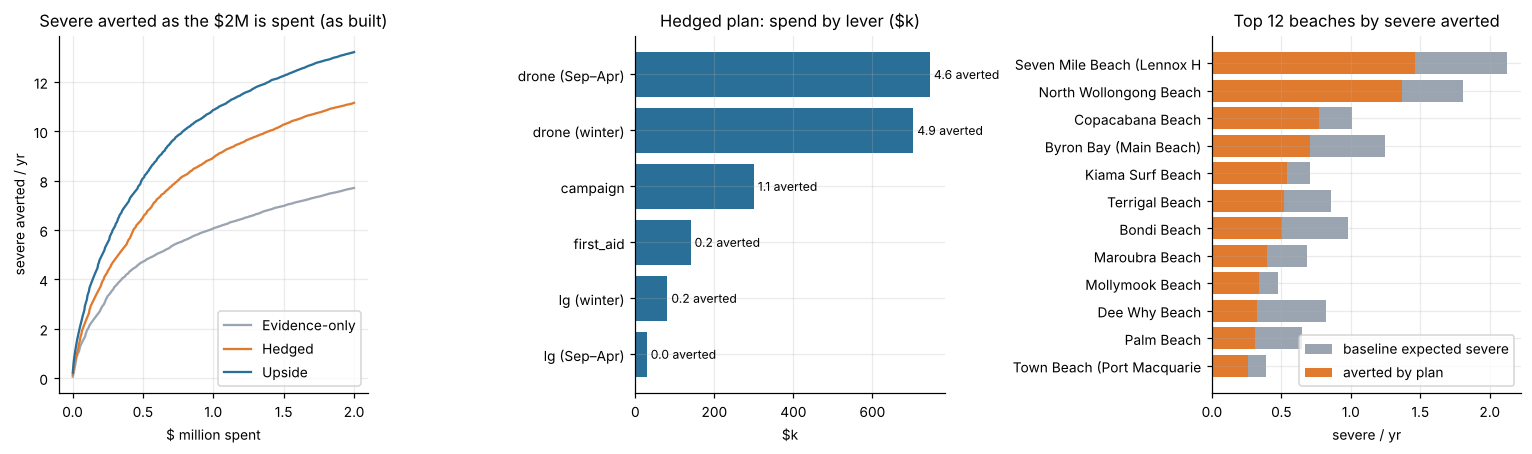

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
for name, c in zip(runs, [GREY, ORANGE, BLUE]):
    l = runs[name]['log']; ax[0].plot(l.cum_cost / 1e6, l.averted.cumsum(), color=c, label=name)
ax[0].set(title='Severe averted as the $2M is spent (as built)', xlabel='$ million spent', ylabel='severe averted / yr'); ax[0].legend()
bl = by_lever.sort_values('spend'); ax[1].barh(bl.index, bl.spend / 1e3, color=BLUE)
for y, (s, a) in enumerate(zip(bl.spend, bl.averted_model)): ax[1].text(s / 1e3 + 10, y, f'{a:.1f} averted', va='center', fontsize=8)
ax[1].set(title=f'{REC} plan: spend by lever ($k)', xlabel='$k')
top = beach_tab.nlargest(12, 'averted')[::-1]
ax[2].barh([n[:26] for n in top.index], top.baseline_severe, color=GREY, label='baseline expected severe')
ax[2].barh([n[:26] for n in top.index], top.averted, color=ORANGE, label='averted by plan')
ax[2].set(title='Top 12 beaches by severe averted', xlabel='severe / yr'); ax[2].legend(loc='lower right')
plt.tight_layout(); plt.show()

**What the plan does**
- **About 73% goes to drone hours.** That is $0.75M in Sep–Apr (more hours on existing kit, plus new kits at high-risk beaches without drones) and $0.70M extending winter hours. Each is worth about 0.6–0.7 severe incidents averted per $100k.
- **Campaigns get 15%**: 20 postcodes at $15k each.
- **First aid gets 7%**, in 4 postcodes. It is the lowest-confidence line, and the first to cut if flags or PA are added (§4).
- **Lifeguards get about 5%**: winter patrol hours, almost all at Seven Mile Beach (Lennox Head), which is unpatrolled in winter and has the highest risk in the state.
- **The plan is concentrated.** Seven Mile Beach and North Wollongong alone avert about 2.8 of the ~11–13, which matches the EDA's "where" story.

## 4. Flags and PA systems: break-even, not estimates
The data cannot estimate flag or PA effects (too few switch events), so they are not in the optimisation. Instead we ask: **how large would their effect need to be to beat the last dollar of the plan?**

In [8]:
last_rate = log['averted_per_$100k'].tail(25).mean() / 1e5          # severe averted per $ at the margin
bb = beach_tab.baseline_severe.to_frame()
static = BASE.drop_duplicates('beach_nm').set_index('beach_nm')[['flags', 'pa_system']]
be = bb.join(static)
be['flags_breakeven_pct'] = np.where(be['flags'] == 0, 100 * COSTS['flags'] * last_rate / be.baseline_severe, np.nan)
be['pa_breakeven_pct'] = np.where(be.pa_system == 0, 100 * COSTS['pa_year1'] * last_rate / be.baseline_severe, np.nan)
print(f'marginal value of the last plan dollar: {last_rate * 1e5:.3f} severe averted per $100k')
print(f'beaches without flags: {(be['flags'] == 0).sum()}, without PA: {(be.pa_system == 0).sum()}')
display(be[be['flags'] == 0].sort_values('flags_breakeven_pct').head(10).round(2))
display(be[be.pa_system == 0].sort_values('pa_breakeven_pct').head(10).round(2))

marginal value of the last plan dollar: 0.194 severe averted per $100k
beaches without flags: 24, without PA: 37


,baseline_severe,flags,pa_system,flags_breakeven_pct,pa_breakeven_pct
beach_nm,,,,,
Seven Mile Beach (Lennox Head),2.12,0,0,0.46,2.46
Byron Bay (Main Beach),1.25,0,1,0.78,NaN
Palm Beach,0.65,0,1,1.50,NaN
Mona Vale Beach,0.25,0,0,3.83,20.66
Woonona Beach,0.23,0,0,4.26,23.03
Merimbula Main Beach,0.16,0,1,6.10,NaN
North Narrabeen Beach,0.15,0,0,6.37,34.39
Newcastle Beach,0.15,0,1,6.43,NaN
Austinmer Beach,0.13,0,0,7.61,41.11


,baseline_severe,flags,pa_system,flags_breakeven_pct,pa_breakeven_pct
beach_nm,,,,,
Seven Mile Beach (Lennox Head),2.12,0,0,0.46,2.46
North Wollongong Beach,1.81,1,0,NaN,2.89
Dee Why Beach,0.82,1,0,NaN,6.37
Maroubra Beach,0.69,1,0,NaN,7.60
Manly Beach,0.60,1,0,NaN,8.70
Cronulla Beach,0.48,1,0,NaN,10.80
Mollymook Beach,0.47,1,0,NaN,11.01
Coogee Beach,0.37,1,0,NaN,13.97
North Cronulla Beach,0.33,1,0,NaN,15.67


**Flags** cost $5,000. To beat the plan's marginal dollar they need to cut severe incidents by only **0.5% at Seven Mile Beach, 0.8% at Byron Bay and 1.5% at Palm Beach**. The (very uncertain) screening estimate was OR ≈ 0.9, about a 10% cut.

**PA systems** cost $27k in year one. They break even at about 2.5–3% at Seven Mile Beach and North Wollongong, but need 6%+ elsewhere.

**Recommendation:** fund flags at those three beaches, and PA at Seven Mile Beach and North Wollongong. Present these as **low-regret, judgement-based add-ons** (about $69k), funded by trimming the plan's last first-aid steps, not as model results.

## 5. Caveats for the panel, and how next year's data resolves them
1. **Winter drone effect: extrapolated.** It is the plan's biggest bet. Roll the extra winter hours out to *some* qualifying beaches first, or stagger them by month, so 2026–27 data identifies the winter effect the same way the original drone rollout identified the summer one.
2. **Lifeguard severity effect: an upper bound.** On/off-duty contrasts partly reflect time of day.
3. **First aid's benefit is uncertain** (P(OR < 1) ≈ 0.73), and the plan gives it little.
4. **The decision uses expected values.** The 80% bands in §2 carry parameter uncertainty only. The realised count next year will scatter by about ±√20 ≈ ±4–5 around the expectation, so one year's count won't settle whether the plan worked. Track rates against the model's counterfactual.
5. **Diminishing returns are model-implied.** The concave pieces (coverage saturation, sqrt campaigns, bounded probabilities) are fitted or structural. Effects beyond the observed lever ranges are blocked by the caps.

In [9]:
for name, r in runs.items():
    r['log'].to_csv(OUT + f'greedy_log_{name}.csv', index=False)
    ba.plan_panel(BASE, ev, r['plan']).to_csv(OUT + f'plan_panel_{name}.csv', index=False)
summary.to_csv(OUT + 'robustness_matrix.csv'); beach_tab.to_csv(OUT + f'beach_plan_{REC}.csv'); price.to_csv(OUT + 'price_list.csv', index=False)
be.to_csv(OUT + 'flags_pa_breakeven.csv')
print(sorted(os.listdir(OUT)))

['beach_plan_Hedged.csv', 'flags_pa_breakeven.csv', 'greedy_log_Evidence-only.csv', 'greedy_log_Hedged.csv', 'greedy_log_Upside.csv', 'plan_panel_Evidence-only.csv', 'plan_panel_Hedged.csv', 'plan_panel_Upside.csv', 'price_list.csv', 'robustness_matrix.csv']
